# APID 18 exploration

APID 18 is the one with the text records (`F4`, `F6`, `F9`) that `find_apids.ipynb` found. The text looks like the
output of a GPS receiver (one of the records is a "Phoenix s/w version" line, and Phoenix is a GPS receiver family).
Questions:

1. How are the packets framed, and how are the records laid out?
2. What are the fields, and do they behave like GPS measurements?
3. Is there a position (ECEF vector, or latitude / longitude) in it? That would be the first position-like data
   that we can decode, and it is what we need for the Sun / attitude problem.
4. Anything LYRA?

In [1]:
import re
from collections import Counter, defaultdict
from dataclasses import dataclass
from datetime import UTC, datetime, timedelta
from itertools import pairwise
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from cadu import HEADER_LEN, iter_packets, packet_apid

SWAP_APID = 20


def packet_timestamp(payload: bytes) -> int | None:
    """satdump's reading of a SWAP image time, as extract_images.py had it: days in bytes 0-1, milliseconds in 2-5.

    Wrong (bytes 1-6 are the tick and its fraction, see APID_20.ipynb), kept here to show the discrepancy below.
    """
    days, milliseconds = int.from_bytes(payload[0:2]), int.from_bytes(payload[2:6])
    if days > 1000:  # the event packets of APID 20 have garbage here
        return None
    return (18630 + days) * 86400 + milliseconds // 1000 + 4 * 3600

In [2]:
CADU_DIR = Path("cadus")
APID = 18

# Same header as the APID 2 and 22 packets: 6 byte primary header, secondary header, marker, tick counter, 2 byte
# data length at 21, data from 23 and a CRC-16 as the last 2 bytes. The data is a text frame:
# STX, the text, 2 hex digits of checksum, ETX.
SECONDARY_HEADER = bytes.fromhex("100889")
TIME_OFFSET = 11
DATA_OFFSET = 23
CRC_LEN = 2
STX = 0x02
ETX = 0x03

GPS_EPOCH = datetime(1980, 1, 6, tzinfo=UTC)
SECONDS_PER_WEEK = 604800
L1_WAVELENGTH = 299792458 / 1575.42e6  # m

## 1. Load

One pass over the dumps keeps the APID 18 packets and the SWAP image timestamps (to compare the clocks later).

In [3]:
packets: list[tuple[str, int, bytes]] = []  # (file name, vcid, packet)
swap_times: dict[str, list[int]] = defaultdict(list)

for path in sorted(CADU_DIR.glob("*.cadu")):
    for vcid, packet in iter_packets(path):
        apid = packet_apid(packet)
        if apid == APID:
            packets.append((path.name, vcid, packet))
        elif apid == SWAP_APID and len(packet) > HEADER_LEN + 6:
            timestamp = packet_timestamp(packet[HEADER_LEN:])
            if timestamp is not None:
                swap_times[path.name].append(timestamp)
    print(f"processed {path.name}")

print(f"{len(packets)} packets with APID {APID}")
print("per file:", dict(Counter(name for name, _, _ in packets)))
print("per virtual channel:", dict(Counter(vcid for _, vcid, _ in packets)))

processed proba2_dump(1).cadu
processed proba2_dump(10).cadu
processed proba2_dump(11).cadu
processed proba2_dump(12).cadu
processed proba2_dump(2).cadu
processed proba2_dump(3).cadu
processed proba2_dump(4).cadu
processed proba2_dump(5).cadu
processed proba2_dump(6).cadu
processed proba2_dump(7).cadu
processed proba2_dump(8).cadu
processed proba2_dump(9).cadu
processed proba2_dump.cadu
5025 packets with APID 18
per file: {'proba2_dump(1).cadu': 62, 'proba2_dump(10).cadu': 1380, 'proba2_dump(11).cadu': 60, 'proba2_dump(12).cadu': 55, 'proba2_dump(2).cadu': 875, 'proba2_dump(3).cadu': 57, 'proba2_dump(4).cadu': 16, 'proba2_dump(5).cadu': 22, 'proba2_dump(6).cadu': 1187, 'proba2_dump(7).cadu': 33, 'proba2_dump(8).cadu': 1190, 'proba2_dump(9).cadu': 46, 'proba2_dump.cadu': 42}
per virtual channel: {1: 559, 2: 4466}


## 2. Packet types

In [4]:
print("secondary headers:", Counter(packet[6:9].hex() for _, _, packet in packets).most_common(6))
print("lengths:", Counter(len(packet) for _, _, packet in packets).most_common(6))

secondary headers: [('100889', 4932), ('100101', 33), ('100107', 32), ('100501', 22), ('580889', 2), ('10096d', 1)]
lengths: [(73, 2457), (626, 2455), (24, 65), (23, 22), (76, 18), (2209, 1)]


`10 08 89` is the text packet (4 929 of them). `10 01 01` and `10 01 07` are the PUS telecommand verification
reports (service 1, subtypes 1 and 7) that APID 2 also has, and `10 05 01` are 23 byte event reports. The rest is
garbage from lost frames. Only the text packets matter here.

In [5]:
text_packets = [(name, vcid, packet) for name, vcid, packet in packets if packet[6:9] == SECONDARY_HEADER]


def crc16(data: bytes) -> int:
    """CRC-16/CCITT-FALSE."""
    crc = 0xFFFF
    for byte in data:
        crc ^= byte << 8
        for _ in range(8):
            crc = ((crc << 1) ^ 0x1021) & 0xFFFF if crc & 0x8000 else (crc << 1) & 0xFFFF
    return crc


def xor_checksum(text: bytes) -> int:
    value = 0
    for byte in text:
        value ^= byte
    return value


declared = np.array([int.from_bytes(packet[21:23]) for _, _, packet in text_packets])
actual = np.array([len(packet) for _, _, packet in text_packets])
print(f"data length = packet length - 25 in {np.mean(declared == actual - 25):.1%}")
print(
    f"STX first, ETX last in the data: "
    f"{np.mean([p[DATA_OFFSET] == STX and p[-CRC_LEN - 1] == ETX for _, _, p in text_packets]):.1%}"
)

crc_ok = np.array([crc16(packet[:-CRC_LEN]) == int.from_bytes(packet[-CRC_LEN:]) for _, _, packet in text_packets])
print(f"packet CRC-16 ok: {crc_ok.mean():.1%}")


def frame_text(packet: bytes) -> tuple[bytes, bool]:
    """Text of a packet and whether its 2 hex digit checksum (XOR of the text bytes) is right."""
    data = packet[DATA_OFFSET + 1 : -CRC_LEN - 1]
    text, checksum = data[:-2], data[-2:]
    try:
        return text, xor_checksum(text) == int(checksum, 16)
    except ValueError:
        return text, False


checksum_ok = np.array([frame_text(packet)[1] for _, _, packet in text_packets])
print(f"text checksum (XOR of the text bytes) ok: {checksum_ok.mean():.1%}")
print(f"both: {np.mean(crc_ok & checksum_ok):.1%}")

data length = packet length - 25 in 99.8%
STX first, ETX last in the data: 99.8%
packet CRC-16 ok: 99.5%
text checksum (XOR of the text bytes) ok: 99.5%
both: 99.5%


The text is framed as STX, text, checksum, ETX, and the last 2 bytes are the usual CRC-16/CCITT. The text checksum
is two hex digits holding the XOR of all the text bytes. Keep the packets that pass both.

In [6]:
records = [
    (name, vcid, packet) for (name, vcid, packet), ok in zip(text_packets, crc_ok & checksum_ok, strict=True) if ok
]
kinds = Counter(frame_text(packet)[0][:2] for _, _, packet in records)
print(f"{len(records)} good text packets:", dict(kinds))

4908 good text packets: {b'F4': 2448, b'F6': 2443, b'F9': 17}


In [7]:
for kind in (b"F4", b"F6", b"F9"):
    text = next(frame_text(packet)[0] for _, _, packet in records if frame_text(packet)[0].startswith(kind))
    print(f"{kind.decode()} ({len(text)} chars):\n{text.decode()[:200]}\n")

F4 (44 chars):
F482387405780.0182387 193601174  510403879.8

F6 (597 chars):
F622387405780.0000718-0.010725522 1         0.00        +0.000    +0.00 30.5 01  2         0.00        +0.000    +0.00 30.5 00  3         0.00        +0.000    +0.00 30.5 01 10         0.00        +0.

F9 (47 chars):
F990 Phoenix s/w version D09Ep (Proba-2 171204)



## 3. Cadence

Same tick counter as in APID 2 and 22. F4 and F6 alternate, one pair every 10 ticks.

In [8]:
runs: dict[tuple[str, int, bytes], list[int]] = defaultdict(list)
for name, vcid, packet in records:
    runs[name, vcid, frame_text(packet)[0][:2]].append(int.from_bytes(packet[TIME_OFFSET : TIME_OFFSET + 4]))

steps = Counter()
for (_, _, kind), ticks in runs.items():
    if kind in (b"F4", b"F6"):
        steps.update(np.diff(ticks))
print("tick steps between consecutive F4 (or F6) records:", steps.most_common(6))

tick steps between consecutive F4 (or F6) records: [(np.int64(10), 4729), (np.int64(20), 52), (np.int64(12), 20), (np.int64(8), 20), (np.int64(30), 8), (np.int64(9), 6)]


## 4. F4 records

44 characters. Compare several of them to find the field boundaries (fixed width, numbers right-aligned and padded
with spaces).

In [9]:
@dataclass
class Record4:
    file: str
    tick: int
    week: int
    seconds: float  # of the week
    field_a: str
    field_b: int
    counter: int
    prefix: str
    seconds_2: float


def parse_f4(name: str, packet: bytes) -> Record4 | None:
    text = frame_text(packet)[0].decode("latin1")
    if not text.startswith("F4") or len(text) != 44:
        return None
    try:
        return Record4(
            name,
            int.from_bytes(packet[TIME_OFFSET : TIME_OFFSET + 4]),
            int(text[3:7]),
            float(text[7:15]),
            text[15:21],
            int(text[21:26]),
            int(text[26:31]),
            text[33:36],
            float(text[36:44]),
        )
    except ValueError:
        return None


f4 = [record for name, _, packet in records if (record := parse_f4(name, packet))]
print(f"{len(f4)} F4 records parsed")
print("char 2 (kind digit):", Counter(frame_text(p)[0][2:3] for _, _, p in records if frame_text(p)[0][:2] == b"F4"))
print("weeks:", sorted(Counter(r.week for r in f4).items()))
print("field a:", Counter(r.field_a for r in f4).most_common(6))
print("prefix before the second time:", Counter(r.prefix for r in f4))
print("field b:", min(r.field_b for r in f4), "-", max(r.field_b for r in f4))
print("counter:", min(r.counter for r in f4), "-", max(r.counter for r in f4))

2445 F4 records parsed
char 2 (kind digit): Counter({b'8': 2448})
weeks: [(2378, 26), (2379, 728), (2380, 1655), (2387, 36)]
field a: [('182380', 1217), ('182379', 732), ('182381', 460), ('182387', 36)]
prefix before the second time: Counter({'510': 2445})
field b: -5226 - 1937
counter: 1150 - 1193


Reading it:

* `week` and `seconds` look like a GPS week and second of the week (seconds below 604 800; they step by 10.0 from
  one record to the next, as the ticks do).
* The second time (`seconds_2`) stays the same for several records and then jumps, and is always earlier than the
  first. It looks like the time of the last update of something (a fix, an ephemeris).
* `field_a` seems to be a 1 followed by a second week number; `field_b` and `counter` are slow counters.

age of the second time: median 702 s, range 2 to 42925 s


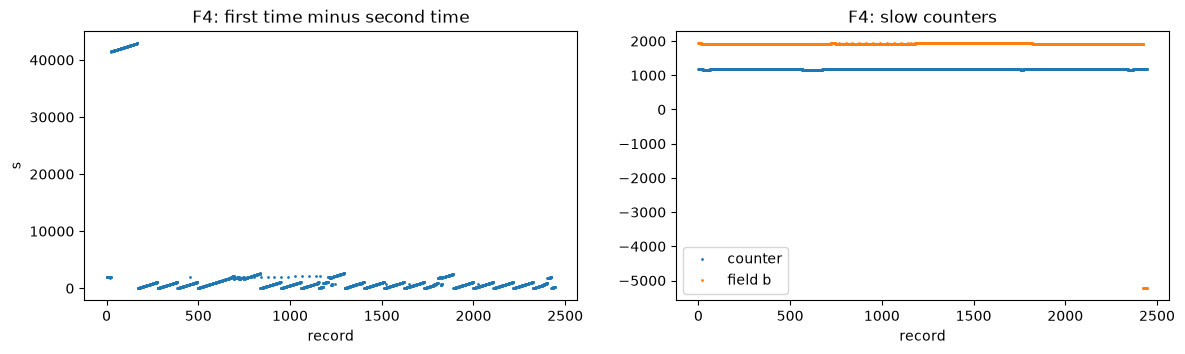

In [10]:
age = np.array([(r.seconds - r.seconds_2) % SECONDS_PER_WEEK for r in f4])
print(f"age of the second time: median {np.median(age):.0f} s, range {age.min():.0f} to {age.max():.0f} s")

fig, (ax_age, ax_counter) = plt.subplots(1, 2, figsize=(14, 3.5))
ax_age.plot(age, ".", markersize=2)
ax_age.set(title="F4: first time minus second time", xlabel="record", ylabel="s")
ax_counter.plot([r.counter for r in f4], ".", markersize=2, label="counter")
ax_counter.plot([r.field_b for r in f4], ".", markersize=2, label="field b")
ax_counter.legend()
ax_counter.set(title="F4: slow counters", xlabel="record")
plt.show()

## 5. F6 records

597 characters: a header and 12 blocks, one per receiver channel. A block is a satellite number (`0` = unused
channel), three numbers, a 4th with one decimal and a hex status.

In [11]:
BLOCK = re.compile(r"\s*(\d+)\s+(-?\d+\.\d+)\s+([+-]\d+\.\d+)\s+([+-]\d+\.\d+)\s+(\d+\.\d)\s+([0-9A-F]{2})")
HEADER_CHARS = 33


@dataclass
class Block:
    prn: int
    pseudorange: float  # provisional names, see below (the 1st number is a range with the clock offset in it)
    phase: float
    range_rate: float
    cn0: float
    status: int


@dataclass
class Record6:
    file: str
    tick: int
    week: int
    seconds: float
    field_6: str
    clock: float
    blocks: list[Block]


def parse_f6(name: str, packet: bytes) -> Record6 | None:
    text = frame_text(packet)[0].decode("latin1")
    if not text.startswith("F6"):
        return None
    try:
        record = Record6(
            name,
            int.from_bytes(packet[TIME_OFFSET : TIME_OFFSET + 4]),
            int(text[3:7]),
            float(text[7:15]),
            text[15:21],
            float(text[21:HEADER_CHARS]),
            [],
        )
    except ValueError:
        return None
    position = HEADER_CHARS
    while match := BLOCK.match(text, position):
        prn, a, b, c, d, status = match.groups()
        record.blocks.append(Block(int(prn), float(a), float(b), float(c), float(d), int(status, 16)))
        position = match.end()
    return record if not text[position:].strip() else None  # all of the text must be blocks


f6 = [record for name, _, packet in records if (record := parse_f6(name, packet))]
print(f"{len(f6)} F6 records parsed, blocks per record: {Counter(len(r.blocks) for r in f6)}")
print("field 6 (chars 15-21):", Counter(r.field_6 for r in f6).most_common(5))
print("clock field:", min(r.clock for r in f6), "-", max(r.clock for r in f6))

2443 F6 records parsed, blocks per record: Counter({12: 2443})
field 6 (chars 15-21): [('000018', 209), ('000718', 52), ('000818', 48), ('001018', 48), ('000918', 47)]
clock field: -0.014251272 - 0.0738574


In [12]:
blocks = [(record, block) for record in f6 for block in record.blocks]
print("status values:", {hex(k): v for k, v in Counter(b.status for _, b in blocks).most_common()})
print("satellite numbers:", sorted(Counter(b.prn for _, b in blocks).items()))
print(
    "4th field of blocks that carry no data:", Counter(b.cn0 for _, b in blocks if b.pseudorange == 0).most_common(4)
)
tracked = [(record, block) for record, block in blocks if block.status == 0x1F]
print(f"{len(tracked)} blocks with status 0x1F, {sum(b.pseudorange != 0 for _, b in blocks)} with data")
print("data in a block without 0x1F:", sum(b.pseudorange != 0 for _, b in blocks if b.status != 0x1F))
for name in ("pseudorange", "phase", "range_rate", "cn0"):
    values = np.array([getattr(block, name) for _, block in tracked])
    print(f"  {name:12s} min {values.min():16.2f} median {np.median(values):16.2f} max {values.max():16.2f}")

status values: {'0x0': 18602, '0x1': 7434, '0x1f': 3052, '0x7': 103, '0xf': 87, '0x3': 38}
satellite numbers: [(0, 3924), (1, 36), (2, 304), (3, 36), (4, 20), (5, 1504), (6, 16), (7, 1136), (8, 1129), (9, 362), (10, 1490), (12, 16), (13, 2101), (14, 788), (15, 2076), (16, 2046), (17, 36), (18, 2363), (19, 16), (21, 569), (22, 412), (23, 2069), (24, 36), (25, 788), (26, 1373), (27, 1651), (28, 111), (29, 1300), (30, 1109), (31, 266), (32, 233)]
4th field of blocks that carry no data: [(30.5, 17652), (0.0, 3924), (31.0, 1993), (32.7, 915)]
3052 blocks with status 0x1F, 3202 with data
data in a block without 0x1F: 150
  pseudorange  min      19315891.90 median      24087871.71 max      52802876.09
  phase        min     -58915602.09 median      -2971031.13 max      29583847.41
  range_rate   min         -8607.65 median          -216.80 max          7990.84
  cn0          min            29.80 median            38.00 max            45.70


Status `0x1F` is the only one with data: a tracked satellite. The data in it:

* 1st number: 20 to 53 million, always positive: a range in metres (the receiver clock offset makes it exceed the
  20-26 thousand km of a real distance),
* 2nd number: of the order of 10 million and either sign: a carrier phase in cycles, if it changes 5.255 times as
  fast as the range (1 / L1 wavelength in m),
* 3rd number: +-8 000: a range rate, if the range changes by this much per second,
* 4th number: 30-46 on tracked channels and 30.5 on unused ones: signal to noise (C/N0 in dB-Hz).

Check the first three against each other for two consecutive records of the same satellite.

In [13]:
by_prn: dict[tuple[str, int], list[tuple[int, Block]]] = defaultdict(list)
for record, block in tracked:
    by_prn[record.file, block.prn].append((record.tick, block))

phase_ratios = []  # d(phase) / d(range)
seconds_between = []  # d(range) / mean range rate
for series in by_prn.values():
    series.sort(key=lambda item: item[0])
    for (t0, b0), (t1, b1) in pairwise(series):
        if t1 - t0 != 10:
            continue
        d_range = b1.pseudorange - b0.pseudorange
        mean_rate = (b0.range_rate + b1.range_rate) / 2
        if abs(d_range) > 100 and abs(mean_rate) > 500:
            phase_ratios.append((b1.phase - b0.phase) / d_range)
            seconds_between.append(d_range / mean_rate)
print(f"{len(phase_ratios)} pairs of consecutive records")
print(f"d(phase)/d(range): median {np.median(phase_ratios):.4f}   (1 / wavelength = {1 / L1_WAVELENGTH:.4f})")
print(f"d(range) / range rate: median {np.median(seconds_between):.2f} s, the records are 10 ticks apart")

2819 pairs of consecutive records
d(phase)/d(range): median 5.2550   (1 / wavelength = 5.2550)
d(range) / range rate: median 10.00 s, the records are 10 ticks apart


Both checks work: the 2nd number is the 1st divided by the L1 wavelength (so a carrier phase in cycles), and the 3rd
one is the range rate in m/s, if the 10 ticks between the records are 10 seconds. That is, **one tick is one second**.

## 6. Clocks

`week` and `seconds` read as a GPS time give a date. Compare it with the tick counter and with the SWAP image dates
of the same dump files.

In [14]:
def gps_time(week: int, seconds: float) -> datetime:
    return GPS_EPOCH + timedelta(weeks=week, seconds=seconds)


by_file = defaultdict(list)
for record in f4:
    by_file[record.file].append(record)

names = sorted(name for name in by_file if swap_times[name])
gps_seconds = np.array([np.median([r.week * SECONDS_PER_WEEK + r.seconds for r in by_file[name]]) for name in names])
ticks = np.array([np.median([r.tick for r in by_file[name]]) for name in names])
swap_seconds = np.array([np.median(swap_times[name]) for name in names])

print(f"{'file':24s} {'GPS time of the F4 records (median)':36s} {'SWAP time (median, satdump)'}")
for name, seconds in zip(names, gps_seconds, strict=True):
    swap = datetime.fromtimestamp(float(np.median(swap_times[name])), UTC)
    print(f"{name:24s} {GPS_EPOCH + timedelta(seconds=seconds):%Y-%m-%d %H:%M:%S}{'':17s} {swap:%Y-%m-%d %H:%M}")

slope_ticks, _ = np.polyfit(ticks, gps_seconds, 1)
slope_swap, _ = np.polyfit(gps_seconds, swap_seconds, 1)
print(f"\nGPS seconds per tick (fit through the files): {slope_ticks:.4f}")
print(f"SWAP (satdump) seconds per GPS second (fit through the files): {slope_swap:.3f}")

file                     GPS time of the F4 records (median)  SWAP time (median, satdump)
proba2_dump(1).cadu      2025-10-09 16:44:15                  2021-11-16 13:25
proba2_dump(10).cadu     2025-08-14 16:00:45                  2021-11-02 04:41
proba2_dump(11).cadu     2025-08-10 03:35:35                  2021-11-01 02:09
proba2_dump(12).cadu     2025-08-08 03:42:55                  2021-10-31 13:50
proba2_dump(2).cadu      2025-08-23 16:05:29                  2021-11-04 12:13
proba2_dump(3).cadu      2025-08-23 03:37:10                  2021-11-04 10:02
proba2_dump(4).cadu      2025-08-21 17:19:35                  2021-11-03 23:57
proba2_dump(5).cadu      2025-08-20 03:00:10                  2021-11-03 15:24
proba2_dump(6).cadu      2025-08-19 03:05:00                  2021-11-03 09:28
proba2_dump(7).cadu      2025-08-18 03:07:30                  2021-11-03 03:10
proba2_dump(8).cadu      2025-08-17 03:12:05                  2021-11-02 21:10
proba2_dump(9).cadu      2025-08-16 03:14

The GPS time runs at exactly one second per tick, within a file and between the files. The GPS dates are in
August to October 2025, and in the same order as the tick counter.

The SWAP image times of `extract_images.py` do not agree: they sit in 2021, and between the files they advance only
about a quarter as fast as the GPS clock. So the 0.256 s per tick that `APID_2.ipynb` and `APID_22.ipynb` took
from the SWAP times is wrong. It is the SWAP timestamps that are off (satdump's day offset of 18630 and the
conversion of the 4 byte millisecond field are the suspects). The ticks of all APIDs seem to be seconds.

**Update (APID_20.ipynb):** solved. Payload bytes 1-6 of a SWAP packet are the tick and its fraction; read as
milliseconds, tick x 256 + fraction / 256 advances 0.256 s per second. And "exactly one second per tick" holds to the 4
digits printed only: per dump, GPS - tick grows by 1.064 s a day (the clock gains 12 ppm), so the tick needs the GPS
offset of its own dump (see the README, "Time").

## 7. Tracking over time

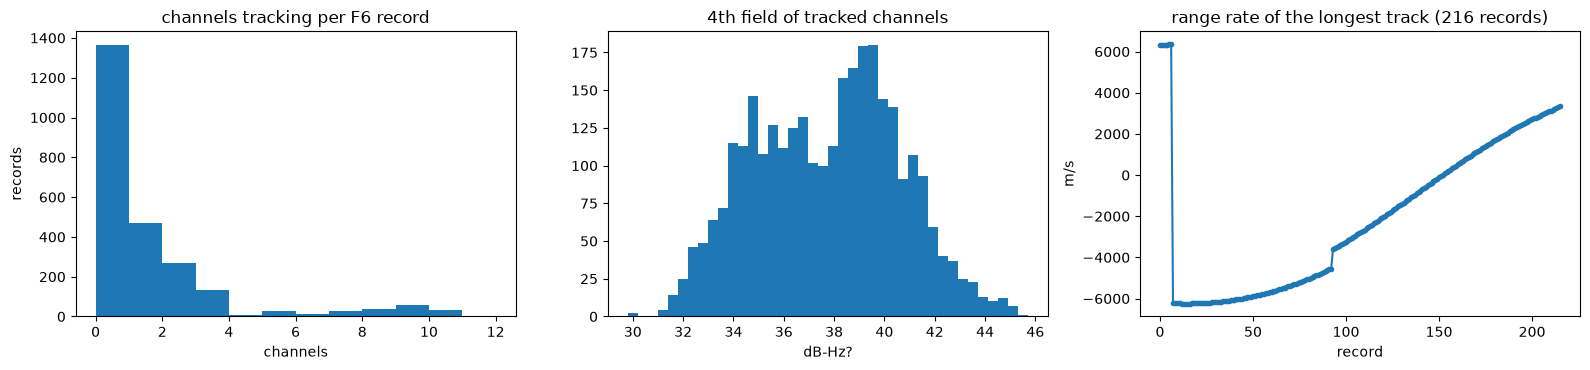

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
tracked_per_record = [sum(b.status == 0x1F for b in r.blocks) for r in f6]
axes[0].hist(tracked_per_record, bins=range(0, 13))
axes[0].set(title="channels tracking per F6 record", xlabel="channels", ylabel="records")
axes[1].hist([b.cn0 for _, b in tracked], bins=40)
axes[1].set(title="4th field of tracked channels", xlabel="dB-Hz?")

series = max(by_prn.values(), key=len)
axes[2].plot([item[1].range_rate for item in series], ".-")
axes[2].set(title=f"range rate of the longest track ({len(series)} records)", xlabel="record", ylabel="m/s")
fig.tight_layout()
plt.show()

## 8. What we know so far

* APID 18 is the GPS receiver's text output. Packet header as in APID 2 / 22, the data a text frame (STX, text,
  XOR checksum as 2 hex digits, ETX), then the packet CRC-16.
* `F4` (44 characters): a week and a second of the week, a second and slower time, and counters. `F6` (597 characters):
  a header (same time, a clock-like float) and 12 channel blocks: satellite number, range, carrier phase, Doppler,
  signal strength and a status; only status `0x1F` carries data.
* **There is no position in it.** `F4` and `F6` hold only time and raw satellite measurements. A position of the
  spacecraft would have to be computed from the ephemerides of the satellites, which are not in these records.
* The receiver clock is a GPS time at one tick per second, so every APID's tick counter is a clock in seconds, and the
  SWAP timestamps from satdump are not (section 6).
* **LYRA:** nothing. **Sun / attitude:** nothing.